# Detecting AI-generated video from its frequency content

Run the cells one at a time. Every clip below is from the **test split**: never used for training or model selection.

In [1]:
import os, sys, joblib
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import CLIPS, FPS, N_FRAMES, MODELS, RESULTS, UNSEEN
from src.data.video_io import read_frames
from src.features.spatial import power_spectrum, radial_spectrum, to_luma
from src.features.temporal import clip_features
from src.features.pixel_baseline import clip_pixel_features
from src.models import data as D
%matplotlib inline

## 1. A real clip and a generated clip

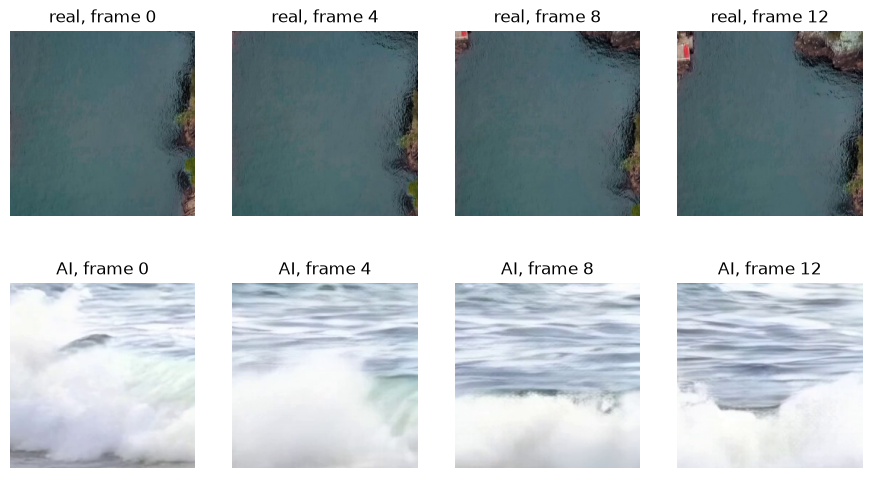

In [2]:
REAL, FAKE = "real_3121923", "ltx_0001"          # two held-out test clips
clips = {"real": read_frames(CLIPS / f"{REAL}.mp4", N_FRAMES, FPS),
         "AI":   read_frames(CLIPS / f"{FAKE}.mp4", N_FRAMES, FPS)}      # each: 14 frames of 256 x 256

fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for r, (name, frames) in enumerate(clips.items()):
    for c, i in enumerate((0, 4, 8, 12)):
        ax[r, c].imshow(frames[i]); ax[r, c].axis("off"); ax[r, c].set_title(f"{name}, frame {i}")

## 2. Their spectra, extracted live

Grey frame -> 2-D FFT -> log power (centre = coarse structure, edge = fine detail) -> average over rings = **radial curve**.

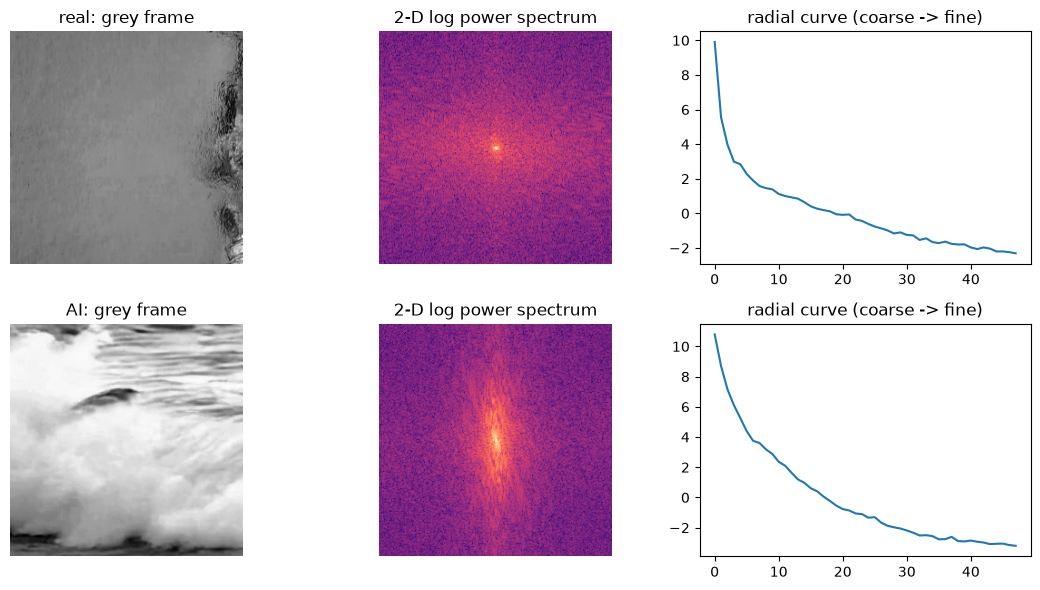

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
for r, (name, frames) in enumerate(clips.items()):
    gray = to_luma(frames[0])
    ax[r, 0].imshow(gray, cmap="gray");                                  ax[r, 0].set_title(f"{name}: grey frame")
    ax[r, 1].imshow(np.log(power_spectrum(gray) + 1e-8), cmap="magma");  ax[r, 1].set_title("2-D log power spectrum")
    ax[r, 2].plot(radial_spectrum(gray));                                ax[r, 2].set_title("radial curve (coarse -> fine)")
    for a in ax[r, :2]: a.axis("off")
plt.tight_layout()

## 3. From one clip to a verdict

Features of the AI clip: frequency features (fine detail + change over time) and pixel features (the control).
Then every model gives the probability that the clip is AI-made.

In [4]:
frames = clips["AI"]
feats, _ = clip_features(frames)
n_freq = len(feats)
feats.update(clip_pixel_features(frames))
print(f"{n_freq} frequency features + {len(feats) - n_freq} pixel features")

stored = D.clean_table().set_index("clip_id").loc[FAKE]       # the same clip's stored features
print("live vs stored features, largest difference:", max(abs(stored[k] - feats[k]) for k in feats))

one = pd.DataFrame([feats])
for name, model_file in [("pixel only", "mlp_pixel"), ("frequency only", "mlp_all"), ("combined", "mlp_fusion")]:
    m = joblib.load(MODELS / f"{model_file}.joblib")
    p = m["model"].predict_proba(np.nan_to_num(one[m["cols"]].to_numpy(np.float32)))[0, 1]
    print(f"{name:15s} P(AI) = {p:.3f}  ->  {'AI' if p >= 0.5 else 'real'}")

263 frequency features + 74 pixel features
live vs stored features, largest difference: 0.0


pixel only      P(AI) = 0.897  ->  AI
frequency only  P(AI) = 0.997  ->  AI
combined        P(AI) = 0.993  ->  AI


## 4. Pixel-only vs frequency-only vs combined, on the same held-out clips

The same 267 test clips, the same trained models, three feature sets (the stored features of these clips; step 3 showed that live extraction gives identical values). AUROC: 1.0 = perfect, 0.5 = guessing.

                     pixel  frequency  combined
ModelScope (unseen)  0.611      0.792     0.738
Wan2.1 (unseen)      0.821      0.677     0.811
seen generators      0.881      0.960     0.976


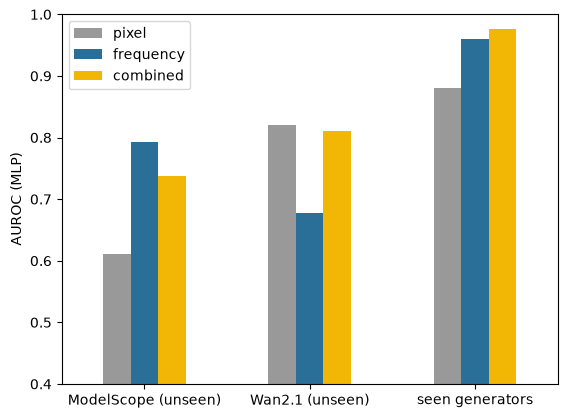

In [5]:
df = D.clean_table()
test = df[(df.split == "test") & ~df.aug.astype(bool)]
real = test.generator == "real"
sets = {"seen generators": ~test.generator.isin(UNSEEN),
        "ModelScope (unseen)": real | (test.generator == "modelscope"),
        "Wan2.1 (unseen)": real | (test.generator == "wan")}

table = {}
for sname, mask in sets.items():
    t = test[mask]
    for feat_name, model_file in [("pixel", "mlp_pixel"), ("frequency", "mlp_all"), ("combined", "mlp_fusion")]:
        m = joblib.load(MODELS / f"{model_file}.joblib")
        p = m["model"].predict_proba(np.nan_to_num(t[m["cols"]].to_numpy(np.float32)))[:, 1]
        table[(sname, feat_name)] = roc_auc_score(t.label, p)

result = pd.Series(table).unstack()[["pixel", "frequency", "combined"]].round(3)
print(result.to_string())
result.plot.bar(rot=0, ylim=(0.4, 1), ylabel="AUROC (MLP)", color=["#999999", "#2a6f97", "#f2b705"]);

## 5. Same numbers as the stored results?

In [6]:
stored = pd.read_csv(RESULTS / "test_metrics.csv")
stored = stored[stored.set == "seen_test"].set_index("model").auroc
print("seen generators, MLP:  live  vs  stored")
for feat_name, model_file in [("pixel", "mlp_pixel"), ("frequency", "mlp_all"), ("combined", "mlp_fusion")]:
    print(f"  {feat_name:10s} {result.loc['seen generators', feat_name]:.3f}  {stored[model_file]:.3f}")

seen generators, MLP:  live  vs  stored
  pixel      0.881  0.881
  frequency  0.960  0.960
  combined   0.976  0.976
